#### Project Overview

In 2026, financial institutions face strict enforcement under laws like the **EU AI Act** and **ECOA (Equal Credit Opportunity Act)** to prove their automated underwriting models do not penalize protected groups or misprice credit risk.

This poject focuses on carrying out hypothesis tests on two important features that financial institutions face strict enforcement.

#### Project Questions 
**Hypothesis 1**. Is there a statistically significant difference in fraud flags (fraud_bool), between older applicants (customer_age >= 50) and younger applicants (customer_age < 50)? 

**Hypothesis 2**. Among legitimate applicants, (fraud_Bool == 0), does automated (credit_risk_score) differ significantly between older applicants (=> 50) and younger applicants (< 50)? ( Tests whether an automated risk model assigns systematically harsher risk scores to older customers even when they are legitimate. )

#### Data Choice:
The NeuIPS BAF suite was created to benchmark fairness and bias in banking.

##### Exploratory Data Analysis (EDA)

In [71]:
# Importing libraries

import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

In [72]:
# loading the dataset to pandas

df = pd.read_csv('../data/raw/Base.csv')

df.head(12)

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0
5,0,0.6,0.294840,-1,369,30,0.024232,-1.232556,AD,1204,...,0,200.0,0,INTERNET,6.987316,linux,1,1,0,0
6,0,0.2,0.773085,22,4,40,0.006919,-0.544676,AB,1998,...,0,200.0,0,INTERNET,28.199923,x11,1,1,0,0
7,0,0.8,0.153880,-1,103,40,0.045122,-1.101184,AB,1548,...,1,200.0,0,INTERNET,11.234264,other,1,1,0,0
8,0,0.3,0.523655,21,2,30,0.035206,-0.955737,AB,1781,...,0,200.0,0,INTERNET,5.329387,other,1,1,0,0
9,0,0.8,0.834475,-1,134,20,0.017245,-1.356393,AD,3113,...,0,1500.0,0,INTERNET,4.103970,other,1,1,0,0


In [73]:
df.shape

(1000000, 32)

In [74]:
# investigating data  and types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  str    
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000000 non-nul

In [75]:
# checking for duplicates

df.duplicated().any()

np.False_

In [76]:
df.isna().sum()

fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

In [77]:
df.describe()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,...,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.0,1000000.000000
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661499,1572.692049,5665.296605,...,0.889676,10.839303,0.222988,515.851010,0.025242,7.544940,0.576947,1.018312,0.0,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,1005.374565,3009.380665,...,0.313293,12.116875,0.416251,487.559902,0.156859,8.033106,0.494044,0.180761,0.0,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,1.000000,-170.603072,...,0.000000,-1.000000,0.000000,190.000000,0.000000,-1.000000,0.000000,-1.000000,0.0,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,894.000000,3436.365848,...,1.000000,-1.000000,0.000000,200.000000,0.000000,3.103053,0.000000,1.000000,0.0,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,1263.000000,5319.769349,...,1.000000,5.000000,0.000000,200.000000,0.000000,5.114321,1.000000,1.000000,0.0,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,1944.000000,7680.717827,...,1.000000,25.000000,0.000000,500.000000,0.000000,8.866131,1.000000,1.000000,0.0,5.000000
max,1.000000,0.900000,0.999999,383.000000,428.000000,90.000000,7.845690e+01,112.956928,6700.000000,16715.565404,...,1.000000,32.000000,1.000000,2100.000000,1.000000,85.899143,1.000000,2.000000,0.0,7.000000


In [78]:
# investing the statistics of credit risk score 

df['credit_risk_score'].describe()

# why is risk score having negative values?

count    1000000.000000
mean         130.989595
std           69.681812
min         -170.000000
25%           83.000000
50%          122.000000
75%          178.000000
max          389.000000
Name: credit_risk_score, dtype: float64

In [79]:
# How many negative values?

df[df['credit_risk_score'] < 0]['credit_risk_score'].count() 

# refering back to the dataset dictionary, concerning credit_risk_score: "Internal score of application risk. Ranges between [ -176, 387 ]". 
# unlike the classic used credit score FICO-style Score that has a common range from (300 - 850), 
# the credit risk score in this dataset normally has negative values, based on the discription
# we will take higher values to mean greater risks. and lower values (even negatives), to mean lesser risks

np.int64(14445)

In [80]:
# investigating the statistics of customer age data field

df['customer_age'].describe()

count    1000000.000000
mean          33.689080
std           12.025799
min           10.000000
25%           20.000000
50%           30.000000
75%           40.000000
max           90.000000
Name: customer_age, dtype: float64

In [81]:
# checking the distribution of customer ages

df['customer_age'].value_counts()

# ages in the dataset are in decades (10-90)

customer_age
30    311433
20    245855
40    238712
50    140353
60     34770
10     20987
70      6517
80      1297
90        76
Name: count, dtype: int64

In [82]:
 # creating a customer classification
 
 df['classification'] = np.where( df['customer_age'] < 50, 'younger', 'older')

#### Extracting valuable data fields for the first hypothesis
1. **fraud_bool**: to extract faudulent applications
2. **customer_age**: to seperate old from young applicants

 **Hypothesis 1**. Is there a statistically significant difference in fraud flags/rates (fraud_bool), between older applicants (customer_age >= 50) and younger applicants (customer_age < 50)? 

*null hypothesis*: There is no statistically significant difference in fraud  rate between older and younger applicants.
*alternative hypothesis*: there is a statistically significant difference in fraud rates between older and younger applicants. 

- we use the standard significant level of 5% (0.05)
- we will use a two proportions z-test to find our p-value
- if p-value is lesser than 0.05, we reject null hypothesis. if p_value is higher than 0.05, we fail to reject null hypothesis

In [83]:
# creating the older applicants group and calculating the fraud rate

older_app = df[df['customer_age'] >= 50]
older_size = len(older_app)

older_fraud = older_app[older_app['fraud_bool'] == 1]
older_fraud_size = len(older_fraud)

older_rate = len(older_fraud) / older_size

older_rate

0.023413637282597412

In [84]:
# creating the younger applicants group and calculating the fraud rate

younger_app = df[df['customer_age'] < 50]
younger_size = len(younger_app)

younger_fraud = younger_app[younger_app['fraud_bool'] == 1] 
younger_fraud_size = len(younger_fraud)

younger_rate = len(younger_fraud) / younger_size

younger_rate

0.008254721311355016

In [85]:
# calculating p-value 

count = [older_fraud_size, younger_fraud_size]

nob = [ older_size, younger_size]

zstats, pvalue = sm.stats.proportions_ztest(count, nob)

print(f'z_stats: {zstats}')
print(f'P-value: {pvalue:.2e}')

z_stats: 56.12506305485793
P-value: 0.00e+00


In [86]:
h1_difference = older_rate - younger_rate

h1_difference

0.015158915971242396

In [87]:
# checking rate uncertainty with confidence interval. Confidence level = 0.95

# calculating unpooled proportion standard error
h1_se = np.sqrt(older_rate * (1 - older_rate) / older_fraud_size + younger_rate * (1 - younger_rate) / younger_fraud_size)

h1lower_ci, h1upper_ci = stats.norm.interval(0.95, h1_difference, h1_se)

print(f'Lower Confidence Interval for hypothesis 1: {h1lower_ci}')
print(f'Upper Confidence Interval for hypothesis 1: {h1upper_ci}')

Lower Confidence Interval for hypothesis 1: 0.010142761855799636
Upper Confidence Interval for hypothesis 1: 0.020175070086685155


Text(0, 0.5, 'fraud rate')

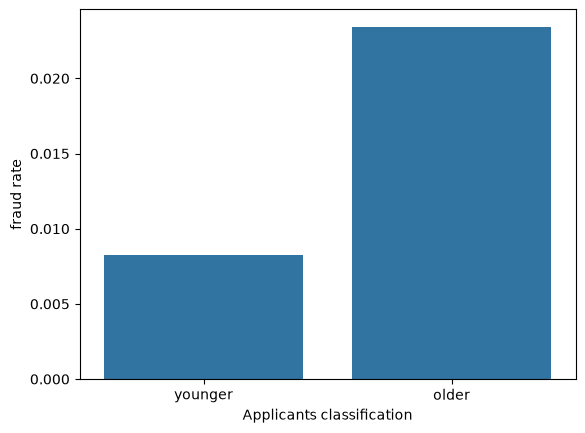

In [97]:
 # visualization of fraud between customer classification

 sns.barplot(data =df, x ='classification', y= 'fraud_bool', errorbar =('ci', False));

 plt.xlabel('Applicants classification')
 plt.ylabel('fraud rate')
 

------

____

#### Extracting valuable data fields for the second hypothesis
1. **fraud_bool**: to extract non faudulent applications
2. **customer_age**: to seperate old from young applicants
3. **credit_risk_score**: to measure the risk score alloted to each group

**Hypothesis 2**. Among legitimate applicants, (fraud_Bool == 0), does automated (credit_risk_score) differ significantly between older applicants (=> 50) and younger applicants (< 50)? ( Tests whether an automated risk model assigns systematically harsher risk scores to older customers even when they are legitimate. )

*null hypothesis*: There is no statistically significant difference in credit_risk_score between older and younger applicants.
*alternative hypothesis*: there is a statistically significant difference in credit_risk_score between older and younger applicants. 

- we use the standard significant level of 5% (0.05)
- we will use welch's two sample t-test to find our p-value
- if p-value is lesser than 0.05, we reject null hypothesis. if p_value is higher than 0.05, we fail to reject null hypothesis

In [ ]:
# extract older group and calculate credit risk score mean


older_applicants = df[df['customer_age'] >= 50]
older_non_fraud = older_applicants[older_applicants['fraud_bool'] == 0]

older_cr = older_non_fraud['credit_risk_score']
older_cr_mean = older_non_fraud['credit_risk_score'].mean()
older_std = older_non_fraud['credit_risk_score'].std()

older_cr_mean

np.float64(146.84410388970952)

In [90]:
# extract younger group and calculate credit risk score mean

younger_applicants = df[df['customer_age'] < 50]
younger_non_fraud = younger_applicants[younger_applicants['fraud_bool'] == 0]

younger_cr = younger_non_fraud['credit_risk_score']
younger_cr_mean = younger_non_fraud['credit_risk_score'].mean()
younger_std = younger_non_fraud['credit_risk_score'].std()

younger_cr_mean

np.float64(126.85798951672523)

In [91]:
# calculate p-value

tstats, pvalue = stats.ttest_ind(older_cr, younger_cr, equal_var = False)

print(f't-stats: {tstats}')
print(f'P-value: {pvalue}')

t-stats: 104.13219309493046
P-value: 0.0


In [92]:
# calculating difference


h2_difference = older_cr_mean - younger_cr_mean

h2_difference

np.float64(19.98611437298429)

In [93]:
# checking rate uncertainty with confidence interval. Confidence level = 0.95

# calculating unpooled mean standard error
h2_se = np.sqrt(older_std ** 2 / older_fraud_size + younger_std ** 2 / younger_fraud_size)

h2lower_ci, h2upper_ci = stats.norm.interval(0.95, h2_difference, h2_se)

print(f'Lower Confidence Interval for hypothesis 1: {h2lower_ci}')
print(f'Upper Confidence Interval for hypothesis 1: {h2upper_ci}')

Lower Confidence Interval for hypothesis 1: 17.22903235379839
Upper Confidence Interval for hypothesis 1: 22.743196392170187


Text(0, 0.5, 'Credit risk score')

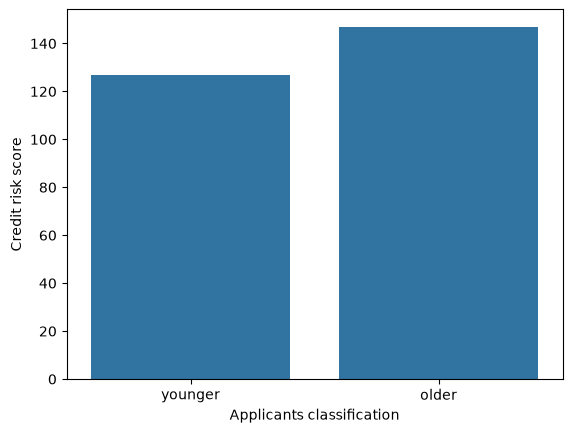

In [96]:
# visualizing credit risk score between customer classification

non_fraud = df[df['fraud_bool'] == 0]

sns.barplot(non_fraud, x= 'classification', y='credit_risk_score', errorbar= ('ci', False))

plt.xlabel('Applicants classification')
plt.ylabel('Credit risk score')

#### Hypothesis 2 result

tstats = 104.132

meaning: The difference between the mean credit risk score between both applicants is just 104.132 standard error away, meaning our confidence is very sizable.


p_value < 0.001

meaning: A p_value below our significant level 0.05, means we reject the null hypothesis. We have enough statistical evidence to claim that there is a significant difference in credit risk score between older applicants and younger applicants


difference = 9.99 point

meaning: Since the difference between the mean credit risk score is (older  -  younger), and the percentage point is +19.99 point, this tells us that among legitimate applications, the automated credit risk score model assigns harsher risk scores to the older group than the younger group with about 19.99 difference.


lower, upper CI = (17 - 22)

meaning: the actual range in risk scores between older and younger applicants is within a (17 - 22) difference.